In [127]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.naive_bayes import GaussianNB
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [128]:
df=pd.read_csv("Iris (1).csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [129]:
df.shape

(150, 6)

In [130]:
df.dtypes

Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object

In [131]:
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [193]:
X=df.drop("Species",axis=1)
Y=df["Species"]

In [194]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.1, random_state=0)

In [195]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

model = GaussianNB()
model.fit(X_train_scaled,Y_train)

,priors,None
,var_smoothing,1e-09


In [196]:
Y_pred = model.predict(X_test_scaled)

In [197]:
cm = confusion_matrix(Y_test, Y_pred)
cm

array([[3, 0, 0],
       [0, 8, 0],
       [0, 0, 4]])

In [198]:
accur=accuracy_score(Y_test,Y_pred)
accur

1.0

In [199]:
D1,A1,A2,A3,D2,A4,A5,A6,D3= cm.ravel()
Accuracy= (D1+D2+D3)/(A1+A2+A3+A4+A5+A6+D1+D2+D3)
Accuracy

np.float64(1.0)

<Axes: xlabel='PetalWidthCm', ylabel='Density'>

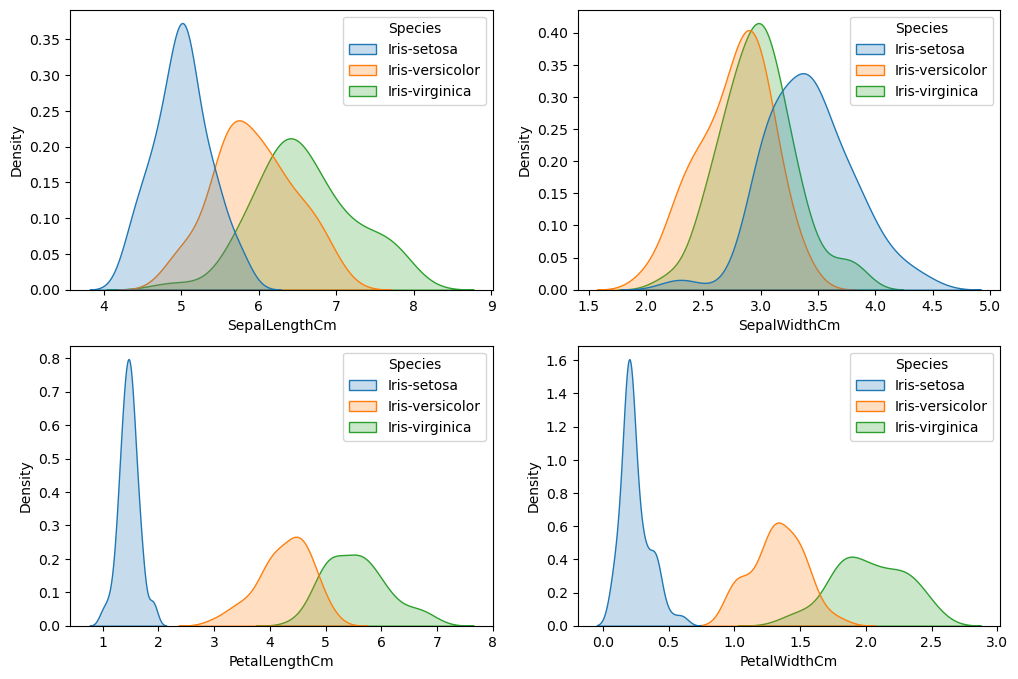

In [200]:
plt.figure(figsize=(12, 8))
plt.subplot(2,2,1)
sns.kdeplot(data=df, x="SepalLengthCm", hue="Species", fill=True)
plt.subplot(2,2,2)
sns.kdeplot(data=df, x="SepalWidthCm", hue="Species", fill=True)
plt.subplot(2,2,3)
sns.kdeplot(data=df, x="PetalLengthCm", hue="Species", fill=True)
plt.subplot(2,2,4)
sns.kdeplot(data=df, x="PetalWidthCm", hue="Species", fill=True)

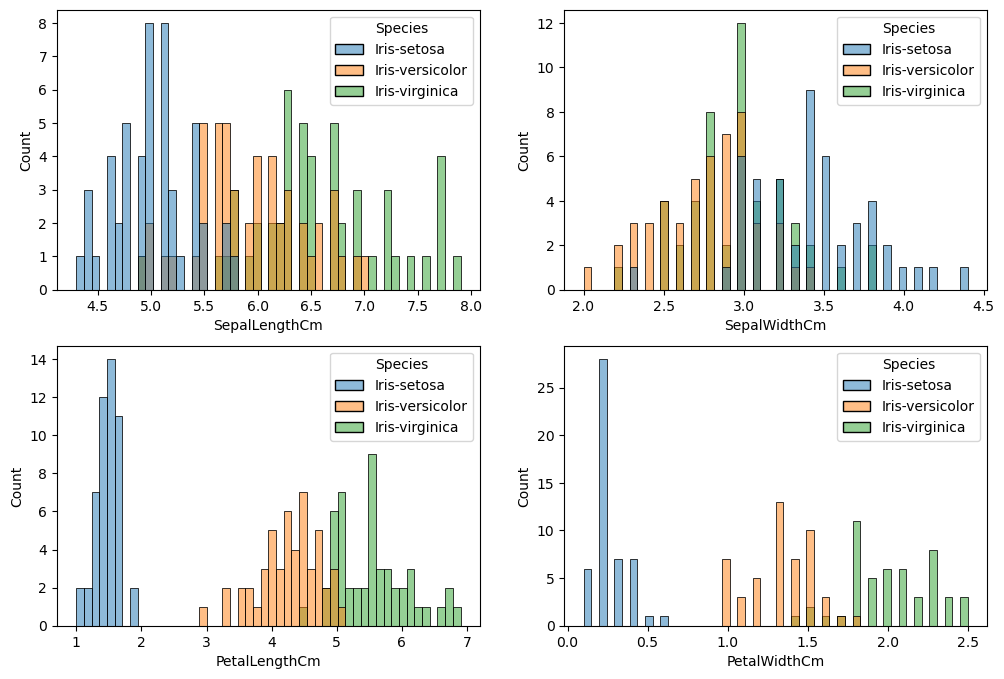

In [208]:
plt.figure(figsize=(12, 8))
plt.subplot(2,2,1)
sns.histplot(data=df, x="SepalLengthCm", hue="Species", bins=50)
plt.subplot(2,2,2)
sns.histplot(data=df, x="SepalWidthCm", hue="Species", bins=50)
plt.subplot(2,2,3)
sns.histplot(data=df, x="PetalLengthCm", hue="Species", bins=50)
plt.subplot(2,2,4)
sns.histplot(data=df, x="PetalWidthCm", hue="Species", bins=50)
plt.show()